# Análises e insights do Data Warehouse

**Censo da Educação Superior (INEP) · 2022 a 2024 · Grupo 6 · Projeto de Integração**

Este notebook executa as três análises do projeto sobre o esquema estrela, confere os resultados contra a referência do perfilamento e gera os gráficos usados na seção 6 do relatório e nos slides. As consultas SQL ficam na pasta `analises/` e também podem ser rodadas direto no pgAdmin ou no `psql`; o notebook as executa, valida e desenha as figuras.

| Análise | Pergunta | Consulta |
| --- | --- | --- |
| 1. EAD × presencial | Como mudou a participação do EAD nos ingressantes e nas matrículas entre 2022 e 2024, por região? | `01a_ead_x_presencial_regiao.sql` e `01b_ead_x_presencial_brasil.sql` |
| 2. Pública × privada e financiamento | Qual a fatia da rede privada nas matrículas, e quanto dos ingressantes privados entram com FIES ou ProUni? | `02_publica_x_privada.sql` |
| 3. Inclusão por área | Como evoluíram os ingressantes pretos, pardos e indígenas e os ingressantes por reserva de vagas, por área CINE? | `03_inclusao_por_area.sql` |

**Pré-requisitos:** PostgreSQL com o banco `censo_superior` e o schema `etl` carregado pelo `01_ETL.ipynb`; pacotes `pandas`, `sqlalchemy`, `psycopg2-binary` e `matplotlib` (ver `requirements.txt`).

**Como rodar:** selecione o kernel `.venv` e execute as células em ordem. A senha do PostgreSQL é pedida na seção 0. Para repetir tudo no caminho ELT, troque a variável `SCHEMA` na seção 0.

**Cuidados que valem para as três análises** (perfilamento §9, §10 e §11):

- Os números são **somas de medidas**, nunca contagem de linhas: o EAD aparece uma vez por polo, então há muito mais linhas do que cursos.
- Vagas e inscritos de EAD existem só em nível Brasil e não são usados aqui, porque nenhuma análise precisa deles.
- As linhas sem município (membros especiais da `dim_localidade`, com `co_municipio` negativo) ficam fora do recorte regional da análise 1, mas entram nas análises 2 e 3.

## 0. Conexão e configurações

A senha é pedida na hora com `getpass`, para não ficar escrita no notebook nem ir para o GitHub. No VS Code, uma caixa de texto aparece no topo da janela.

A função `rodar` lê um arquivo `.sql` da pasta `analises/` e o executa. Os arquivos usam o prefixo `etl.` nas tabelas (para funcionarem direto no pgAdmin), e a função troca esse prefixo pelo schema escolhido em `SCHEMA`.

In [ ]:
from getpass import getpass
from pathlib import Path
from urllib.parse import quote_plus
import textwrap

import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text

USUARIO = "postgres"
HOST = "localhost"
PORTA = 5432
BANCO = "censo_superior"
SCHEMA = "etl"  # para repetir as análises no outro caminho, trocar por "elt"

PASTA_SQL = Path("../analises")
PASTA_FIG = Path("../docs/figuras")
PASTA_FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.alpha": 0.3,
})


def rodar(arquivo):
    """Executa um arquivo de analises/ no schema escolhido e devolve um DataFrame."""
    sql = (PASTA_SQL / arquivo).read_text(encoding="utf-8").replace("etl.", f"{SCHEMA}.")
    return pd.read_sql(sql, engine)

In [2]:
senha = getpass("Senha do PostgreSQL: ")
engine = create_engine(f"postgresql+psycopg2://{USUARIO}:{quote_plus(senha)}@{HOST}:{PORTA}/{BANCO}")

with engine.connect() as conexao:
    print("Conectado:", conexao.execute(text("SELECT version()")).scalar())
    print("Linhas na fato:", conexao.execute(text(f"SELECT COUNT(*) FROM {SCHEMA}.fato_oferta_curso")).scalar())

Conectado: PostgreSQL 18.7 on x86_64-pc-linux-gnu, compiled by gcc (GCC) 16.2.1 20260810, 64-bit
Linhas na fato: 1964978


## 1. Verificação antes das análises

Antes de olhar qualquer resultado, provamos que as consultas não perdem nem duplicam linhas nos `JOIN`s. Para isso, a soma de ingressantes e de matrículas de cada consulta, por ano, precisa ser **igual à referência do perfilamento** (§15), a mesma usada na conferência do ETL.

| Ano | Ingressantes | Matrículas |
| --- | --- | --- |
| 2022 | 4.756.957 | 9.444.116 |
| 2023 | 4.994.192 | 9.977.217 |
| 2024 | 5.010.613 | 10.227.266 |

A única exceção esperada é a análise 1 por região, que **descarta de propósito** as linhas sem município. Para ela, medimos quanto ficou de fora.

Se algum `assert` falhar, não escreva insight sobre esses números: há um `JOIN` perdendo linhas ou o banco está diferente do esperado.

In [3]:
REF = pd.DataFrame(
    {"ing": [4756957, 4994192, 5010613], "mat": [9444116, 9977217, 10227266]},
    index=pd.Index([2022, 2023, 2024], name="ano"),
)

brasil = rodar("01b_ead_x_presencial_brasil.sql")
a1 = rodar("01a_ead_x_presencial_regiao.sql")
a2 = rodar("02_publica_x_privada.sql")
a3 = rodar("03_inclusao_por_area.sql")

assert (brasil.groupby("ano")[["ing", "mat"]].sum().values == REF.values).all(), "análise 1 (Brasil) não fecha"
assert (a2.groupby("ano")[["ing", "mat"]].sum().values == REF.values).all(), "análise 2 não fecha"
assert (a3.groupby("ano")["ing"].sum().values == REF["ing"].values).all(), "análise 3 não fecha"

fora = pd.DataFrame({
    "ingressantes fora do recorte regional": REF["ing"] - a1.groupby("ano")["ing_total"].sum(),
    "matrículas fora do recorte regional": REF["mat"] - a1.groupby("ano")["mat_total"].sum(),
})
fora["% dos ingressantes"] = (100 * fora["ingressantes fora do recorte regional"] / REF["ing"]).round(3)
fora["% das matrículas"] = (100 * fora["matrículas fora do recorte regional"] / REF["mat"]).round(3)

print("Reconciliação OK: as consultas das análises 1 (Brasil), 2 e 3 reproduzem os totais da referência.")
print("\nO que a análise 1 por região deixa de fora (linhas sem município):")
display(fora)

Reconciliação OK: as consultas das análises 1 (Brasil), 2 e 3 reproduzem os totais da referência.

O que a análise 1 por região deixa de fora (linhas sem município):


,ingressantes fora do recorte regional,matrículas fora do recorte regional,% dos ingressantes,% das matrículas
ano,,,,
2022,1799,2826,0.038,0.030
2023,1706,2782,0.034,0.028
2024,1497,2580,0.030,0.025


## 2. Análise 1: EAD × presencial por região

**Pergunta:** como mudou a participação do EAD nos ingressantes e nas matrículas entre 2022 e 2024, por região?

**Tabelas usadas:** `fato_oferta_curso` (medidas `qt_ing` e `qt_mat`), `dim_curso` (`modalidade`), `dim_localidade` (`regiao`) e `dim_tempo` (`ano`).

**Como ler o resultado:**

- A região é a do **local de oferta do curso**. No EAD, é a região do **polo**, e não a do aluno.
- O percentual é a fatia do EAD dentro de cada região e ano (EAD ÷ presencial + EAD).
- As linhas sem município (EAD só em nível Brasil, exterior e não informado) ficam fora do recorte regional; o quanto foi está na tabela da seção 1.

Primeiro o panorama nacional (todas as linhas, sem filtro de região), que serve de contexto para os números regionais.

In [4]:
ing_mod = brasil.pivot(index="ano", columns="modalidade", values="ing")
mat_mod = brasil.pivot(index="ano", columns="modalidade", values="mat")

nacional = pd.DataFrame({
    "ingressantes": ing_mod.sum(axis=1),
    "% ingressantes em EAD": (100 * ing_mod["EAD"] / ing_mod.sum(axis=1)).round(2),
    "matrículas": mat_mod.sum(axis=1),
    "% matrículas em EAD": (100 * mat_mod["EAD"] / mat_mod.sum(axis=1)).round(2),
})
print("Brasil (todas as linhas):")
display(nacional)

ORDEM_REGIOES = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]
pivo_ing = a1.pivot(index="regiao", columns="ano", values="pct_ing_ead")
pivo_mat = a1.pivot(index="regiao", columns="ano", values="pct_mat_ead")
ordem = [r for r in ORDEM_REGIOES if r in pivo_ing.index] + [r for r in pivo_ing.index if r not in ORDEM_REGIOES]
pivo_ing, pivo_mat = pivo_ing.loc[ordem], pivo_mat.loc[ordem]

variacao = pd.DataFrame({
    "ingressantes: 2022 (%)": pivo_ing[2022], "ingressantes: 2024 (%)": pivo_ing[2024],
    "ingressantes: variação (p.p.)": (pivo_ing[2024] - pivo_ing[2022]).round(2),
    "matrículas: 2022 (%)": pivo_mat[2022], "matrículas: 2024 (%)": pivo_mat[2024],
    "matrículas: variação (p.p.)": (pivo_mat[2024] - pivo_mat[2022]).round(2),
})
print("\nPor região (p.p. = pontos percentuais):")
display(variacao)

Brasil (todas as linhas):


,ingressantes,% ingressantes em EAD,matrículas,% matrículas em EAD
ano,,,,
2022,4756957,65.18,9444116,45.86
2023,4994192,66.37,9977217,49.25
2024,5010613,66.81,10227266,50.74



Por região (p.p. = pontos percentuais):


,ingressantes: 2022 (%),ingressantes: 2024 (%),ingressantes: variação (p.p.),matrículas: 2022 (%),matrículas: 2024 (%),matrículas: variação (p.p.)
regiao,,,,,,
Norte,68.58,66.70,-1.88,49.68,51.21,1.53
Nordeste,59.30,60.27,0.97,38.78,43.97,5.19
Centro-Oeste,64.66,64.40,-0.26,45.03,48.61,3.58
Sudeste,64.20,67.97,3.77,45.08,51.67,6.59
Sul,72.50,71.99,-0.51,54.82,57.59,2.77


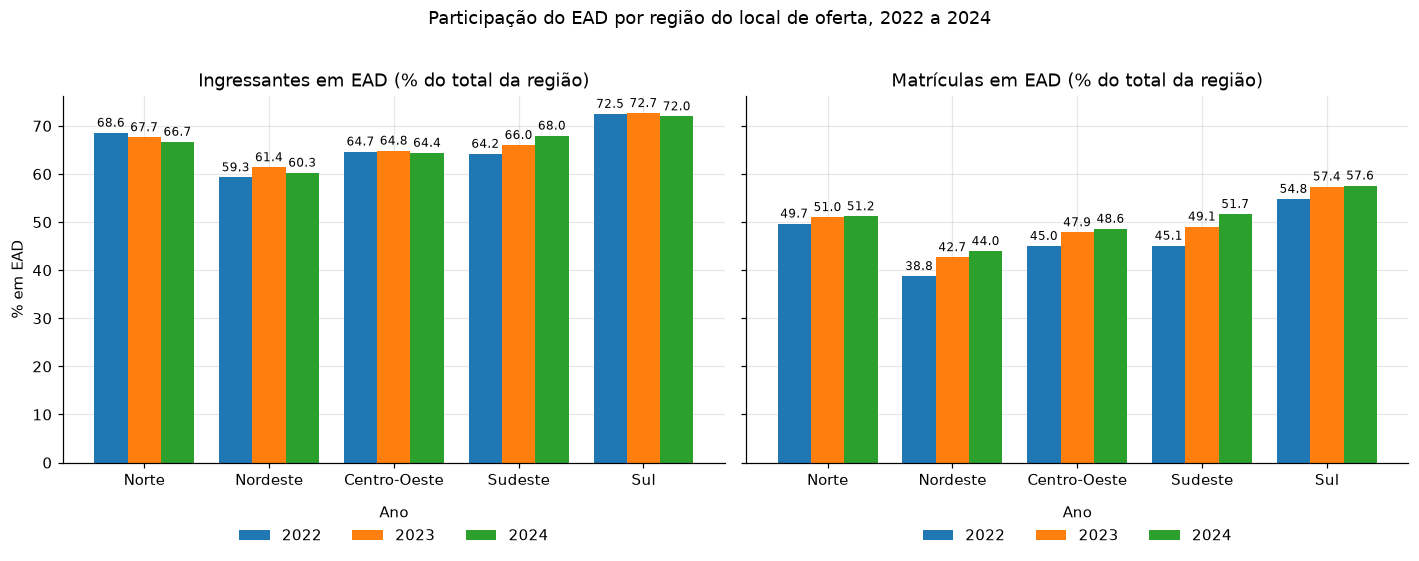

In [5]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for eixo, pivo, titulo in [
    (eixos[0], pivo_ing, "Ingressantes"),
    (eixos[1], pivo_mat, "Matrículas"),
]:
    pivo.plot(kind="bar", ax=eixo, rot=0, width=0.8)
    for container in eixo.containers:
        eixo.bar_label(container, fmt="%.1f", fontsize=8, padding=2)
    eixo.set_title(f"{titulo} em EAD (% do total da região)")
    eixo.set_xlabel("")
    eixo.legend(title="Ano", loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False)
eixos[0].set_ylabel("% em EAD")
fig.suptitle("Participação do EAD por região do local de oferta, 2022 a 2024", y=1.02)
fig.tight_layout()
fig.savefig(PASTA_FIG / "analise1_ead_regiao.png", dpi=200, bbox_inches="tight")
plt.show()

### Insight da análise 1

- **Resultado principal:** o EAD tem 65,18% dos ingressantes em 2022 e 66,81% em 2024 (+1,63 p.p.). Nas matrículas, passa de 45,86% para 50,74% (+4,88 p.p.) e ultrapassa metade do total em 2024.
- **Tendência por região:** o Sudeste foi o que mais mudou (+3,77 p.p. nos ingressantes e +6,59 p.p. nas matrículas). O Nordeste teve o segundo maior aumento nas matrículas (+5,19 p.p.). Norte, Centro-Oeste e Sul ficaram estáveis ou levemente abaixo nos ingressantes (entre -1,88 e -0,26 p.p.).
- **Exceção ou ponto de atenção:** a diferença entre a fatia de ingressantes e a de matrículas caiu de 19,32 para 16,07 p.p. Isso é compatível com as turmas de EAD passando a pesar mais no total de matriculados, mas os dados não confirmam. Em 2024, só Nordeste (43,97%) e Centro-Oeste (48,61%) ficam abaixo de 50% nas matrículas.
- **Limitações:** a região é a do polo (não a do aluno); as linhas sem município ficaram fora do recorte regional (0,030% a 0,038% dos ingressantes); o resultado descreve a oferta registrada no Censo, não a procura.

## 3. Análise 2: pública × privada e financiamento

**Pergunta:** qual a fatia da rede privada nas matrículas, e quanto dos ingressantes privados entram com FIES ou ProUni?

**Tabelas usadas:** `fato_oferta_curso` (`qt_mat`, `qt_ing`, `qt_ing_fies`, `qt_ing_prounii`, `qt_ing_prounip`), `dim_ies` (`rede`) e `dim_tempo` (`ano`).

**Como ler o resultado:**

- A rede vem da `dim_ies`, derivada da categoria administrativa nos três anos (perfilamento §12). A fato aponta para a versão da IES **do próprio ano**.
- `pct_mat` é a fatia de cada rede nas matrículas do ano.
- Os percentuais de FIES e ProUni usam como denominador os ingressantes **da própria rede**. A linha da rede privada responde à segunda pergunta.
- **FIES** é o Fundo de Financiamento Estudantil. **ProUni** tem duas colunas, confirmadas no dicionário do INEP: `QT_ING_PROUNII` (integral) e `QT_ING_PROUNIP` (parcial). O total ProUni é a soma das duas.
- Somar FIES e ProUni assume que um mesmo ingressante não conta nos dois programas. O dicionário não deixa isso explícito, então o total é uma **aproximação**.
- FIES e ProUni só se aplicam a IES privadas. Os valores da rede pública devem ser zero ou quase, e a célula abaixo confere isso.

In [6]:
display(a2)

rede_publica = a2[a2["rede"] == "Pública"][["ano", "ing", "ing_fies", "ing_prouni"]]
print("Conferência: financiamento na rede pública (esperado zero ou muito próximo disso):")
display(rede_publica)

privada = a2[a2["rede"] == "Privada"].set_index("ano")
resumo = privada[["pct_mat", "pct_fies", "pct_prouni", "pct_fies_ou_prouni"]].copy()
resumo.columns = ["% das matrículas do país", "% ingressantes com FIES", "% com ProUni", "% com FIES ou ProUni"]
print("\nRede privada, resumo:")
display(resumo)
print("Variação 2022 → 2024 (p.p.):")
display((resumo.loc[2024] - resumo.loc[2022]).round(2).to_frame("variação (p.p.)"))

,ano,rede,mat,pct_mat,ing,ing_fies,ing_prouni,pct_fies,pct_prouni,pct_fies_ou_prouni
0,2022,Privada,7367363,78.01,4231437,30906,120035,0.73,2.84,3.57
1,2022,Pública,2076753,21.99,525520,142,0,0.03,0.00,0.03
2,2023,Privada,7907851,79.26,4424983,42030,130113,0.95,2.94,3.89
3,2023,Pública,2069366,20.74,569209,137,0,0.02,0.00,0.02
4,2024,Privada,8162199,79.81,4435283,31728,139361,0.72,3.14,3.86
5,2024,Pública,2065067,20.19,575330,69,0,0.01,0.00,0.01


Conferência: financiamento na rede pública (esperado zero ou muito próximo disso):


,ano,ing,ing_fies,ing_prouni
1,2022,525520,142,0
3,2023,569209,137,0
5,2024,575330,69,0



Rede privada, resumo:


,% das matrículas do país,% ingressantes com FIES,% com ProUni,% com FIES ou ProUni
ano,,,,
2022,78.01,0.73,2.84,3.57
2023,79.26,0.95,2.94,3.89
2024,79.81,0.72,3.14,3.86


Variação 2022 → 2024 (p.p.):


,variação (p.p.)
% das matrículas do país,1.80
% ingressantes com FIES,-0.01
% com ProUni,0.30
% com FIES ou ProUni,0.29


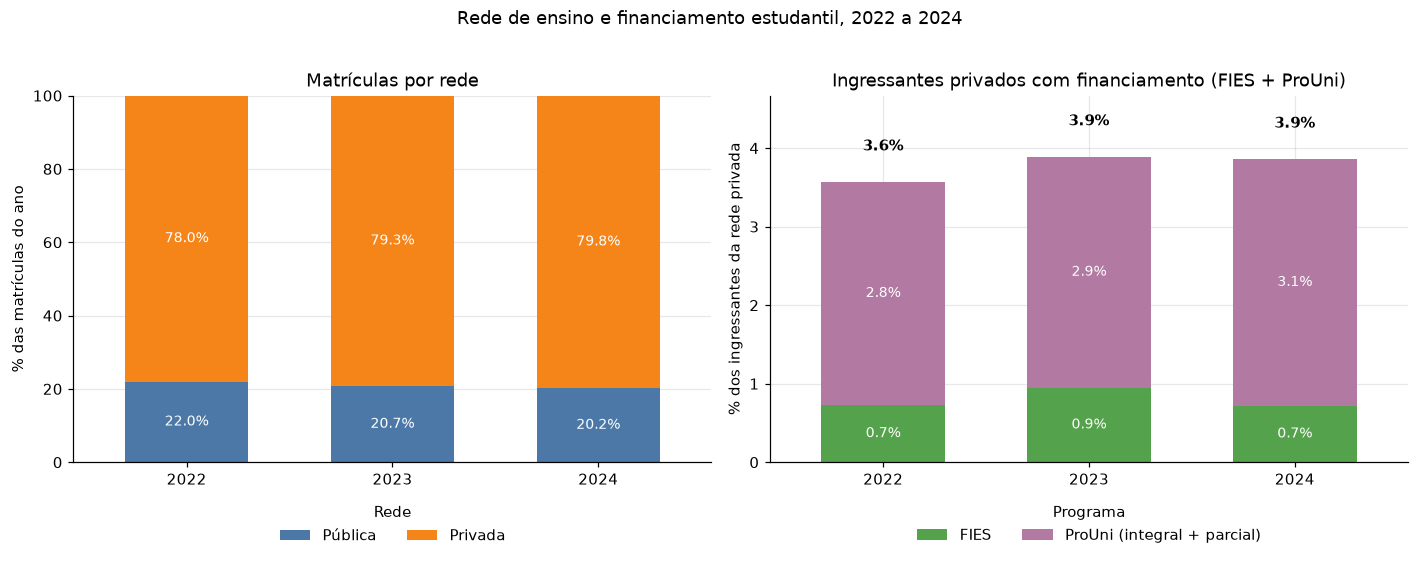

In [7]:
ORDEM_REDE = ["Pública", "Privada"]
CORES_REDE = ["#4C78A8", "#F58518"]

mat_rede = a2.pivot(index="ano", columns="rede", values="pct_mat")[ORDEM_REDE]
financiamento = privada[["pct_fies", "pct_prouni"]]
financiamento.columns = ["FIES", "ProUni (integral + parcial)"]

fig, eixos = plt.subplots(1, 2, figsize=(13, 5))

# Painel A: fatia de cada rede nas matrículas
mat_rede.plot(kind="bar", stacked=True, ax=eixos[0], rot=0, width=0.6, color=CORES_REDE)
for container in eixos[0].containers:
    eixos[0].bar_label(container, fmt="%.1f%%", label_type="center", color="white", fontsize=9)
eixos[0].set_ylim(0, 100)
eixos[0].set_ylabel("% das matrículas do ano")
eixos[0].set_xlabel("")
eixos[0].set_title("Matrículas por rede")
eixos[0].legend(title="Rede", loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)

# Painel B: ingressantes da rede privada com FIES ou ProUni
financiamento.plot(kind="bar", stacked=True, ax=eixos[1], rot=0, width=0.6, color=["#54A24B", "#B279A2"])
for container in eixos[1].containers:
    eixos[1].bar_label(container, fmt="%.1f%%", label_type="center", color="white", fontsize=9)
for posicao, (ano, linha) in enumerate(financiamento.iterrows()):
    eixos[1].text(posicao, linha.sum() + 0.4, f"{linha.sum():.1f}%", ha="center", fontweight="bold")
eixos[1].set_ylim(0, financiamento.sum(axis=1).max() * 1.2)
eixos[1].set_ylabel("% dos ingressantes da rede privada")
eixos[1].set_xlabel("")
eixos[1].set_title("Ingressantes privados com financiamento (FIES + ProUni)")
eixos[1].legend(title="Programa", loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)

fig.suptitle("Rede de ensino e financiamento estudantil, 2022 a 2024", y=1.02)
fig.tight_layout()
fig.savefig(PASTA_FIG / "analise2_rede_financiamento.png", dpi=200, bbox_inches="tight")
plt.show()

### Insight da análise 2

- **Resultado principal:** a rede privada tem 78,01% das matrículas em 2022 e 79,81% em 2024 (+1,80 p.p.). Cerca de 4% dos ingressantes privados entram com FIES ou ProUni (3,57% em 2022 e 3,86% em 2024).
- **Tendência:** o ProUni cresce de forma contínua (2,84% → 2,94% → 3,14%) e responde por 75,6% a 81,5% do total financiado. O FIES oscilou (0,73% → 0,95% → 0,72%) e voltou em 2024 ao nível de 2022.
- **Exceção ou ponto de atenção:** nos ingressantes, a fatia da rede privada caiu levemente (88,95% → 88,52%), o contrário das matrículas. As matrículas privadas cresceram 10,8% e as públicas ficaram estáveis (-0,6%), enquanto os ingressantes públicos cresceram 9,5% contra 4,8% dos privados. A diferença entre as duas fatias (cerca de 89% e 80%) precisa de mais dados para ser explicada.
- **Limitações:** somar FIES e ProUni assume que ninguém conta nos dois (o dicionário não confirma); só esses dois programas entram; a rede é a do próprio ano, derivada da categoria administrativa. FIES na rede pública é residual (69 a 142 ingressantes), tratado como inconsistência pontual do Censo.

## 4. Análise 3: inclusão por área CINE

**Pergunta:** como evoluíram os ingressantes pretos, pardos e indígenas e os ingressantes por reserva de vagas, por área CINE?

**Tabelas usadas:** `fato_oferta_curso` (`qt_ing`, `qt_ing_preta`, `qt_ing_parda`, `qt_ing_indigena`, `qt_ing_reserva_vaga`, `qt_ing_reserva_etnica`), `dim_area_cine` (`area_geral`) e `dim_tempo` (`ano`).

**Como ler o resultado:**

- Usamos a **área geral** da classificação CINE, para os gráficos ficarem legíveis. A área detalhada tem centenas de rótulos.
- `pct_ppi` é a fatia de ingressantes pretos, pardos e indígenas **declarados**. O denominador é o total de ingressantes, inclusive os que não declararam cor/raça, então o valor tende a ficar abaixo do real.
- `pct_reserva_vaga` é a fatia de ingressantes por qualquer programa de reserva de vagas.
- `pct_reserva_etnica` usa a medida `qt_ing_reserva_etnica`, **unificada pelo ETL**: em 2022 e 2023 é a coluna `QT_ING_RVETNICO`, e em 2024 é a soma de `RVPPI + RVQUILO + RVPOVT`. É uma **aproximação** (perfilamento §8). A série fica suave, mas o dicionário não confirma a equivalência. Nos gráficos, as barras de 2024 dessa medida aparecem **hachuradas** por esse motivo.
- Reserva étnica (cerca de 1,5% dos ingressantes) e cor/raça declarada (cerca de 35%) medem coisas diferentes: uma é participação em programa de reserva, a outra é autodeclaração.

Esta análise sustenta o item 17 dos slides, porque mostra uma mudança real de colunas entre 2023 e 2024 e como o grupo a tratou.

In [8]:
display(a3)

por_area = a3.pivot(index="area_geral", columns="ano", values="pct_ppi")
por_area["variação 2022→2024 (p.p.)"] = (por_area[2024] - por_area[2022]).round(2)
print("Pretos, pardos e indígenas declarados (% dos ingressantes), por área:")
display(por_area.sort_values(2024, ascending=False))

nacional3 = a3.groupby("ano")[["ing", "ing_ppi", "ing_reserva_vaga", "ing_reserva_etnica"]].sum()
for coluna in ["ing_ppi", "ing_reserva_vaga", "ing_reserva_etnica"]:
    nacional3[f"% {coluna}"] = (100 * nacional3[coluna] / nacional3["ing"]).round(2)
print("\nTotal nacional:")
display(nacional3)

,ano,area_geral,ing,ing_ppi,pct_ppi,ing_reserva_vaga,pct_reserva_vaga,ing_reserva_etnica,pct_reserva_etnica
0,2022,"Agricultura, silvicultura, pesca e veterinária",125310,40919,32.65,9184,7.33,4402,3.51
1,2023,"Agricultura, silvicultura, pesca e veterinária",134427,44024,32.75,9900,7.36,4670,3.47
2,2024,"Agricultura, silvicultura, pesca e veterinária",127268,44224,34.75,10307,8.10,4991,3.92
3,2022,Artes e humanidades,132960,37504,28.21,4482,3.37,2300,1.73
4,2023,Artes e humanidades,139253,40606,29.16,4875,3.50,2368,1.70
5,2024,Artes e humanidades,143105,44844,31.34,5727,4.00,2752,1.92
6,2022,"Ciências naturais, matemática e estatística",42163,15391,36.50,7755,18.39,3758,8.91
7,2023,"Ciências naturais, matemática e estatística",44272,16342,36.91,8378,18.92,4051,9.15
8,2024,"Ciências naturais, matemática e estatística",44832,16760,37.38,9048,20.18,4637,10.34
9,2022,"Ciências sociais, comunicação e informação",214365,66833,31.18,8938,4.17,4391,2.05


Pretos, pardos e indígenas declarados (% dos ingressantes), por área:


ano,2022,2023,2024,variação 2022→2024 (p.p.)
area_geral,,,,
Programas básicos,39.38,42.46,40.72,1.34
Educação,36.37,38.02,39.52,3.15
"Ciências naturais, matemática e estatística",36.50,36.91,37.38,0.88
Saúde e bem-estar,37.22,37.19,36.89,-0.33
"Engenharia, produção e construção",34.32,34.66,35.44,1.12
"Negócios, administração e direito",32.85,34.82,35.19,2.34
"Agricultura, silvicultura, pesca e veterinária",32.65,32.75,34.75,2.10
Serviços,31.46,33.36,34.53,3.07
Computação e Tecnologias da Informação e Comunicação (TIC),30.90,33.48,34.28,3.38



Total nacional:


,ing,ing_ppi,ing_reserva_vaga,ing_reserva_etnica,% ing_ppi,% ing_reserva_vaga,% ing_reserva_etnica
ano,,,,,,,
2022,4756957,1622249,132758,63925,34.10,2.79,1.34
2023,4994192,1767487,153738,72270,35.39,3.08,1.45
2024,5010613,1804598,171335,83041,36.02,3.42,1.66


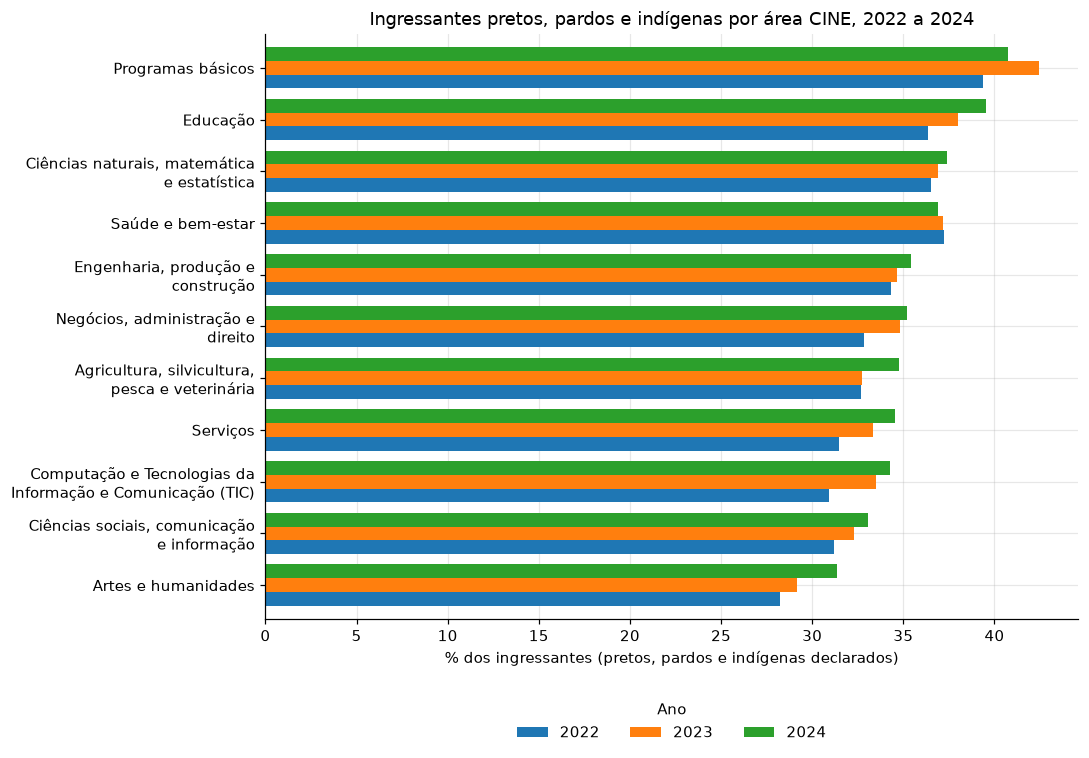

In [9]:
def quebrar(rotulos, largura=30):
    return [textwrap.fill(str(r), largura) for r in rotulos]


# Figura 3a: pretos, pardos e indígenas por área
pivo_ppi = a3.pivot(index="area_geral", columns="ano", values="pct_ppi").sort_values(2024)
pivo_ppi.index = quebrar(pivo_ppi.index)

fig, eixo = plt.subplots(figsize=(10, 7))
pivo_ppi.plot(kind="barh", ax=eixo, width=0.8)
eixo.set_xlabel("% dos ingressantes (pretos, pardos e indígenas declarados)")
eixo.set_ylabel("")
eixo.set_title("Ingressantes pretos, pardos e indígenas por área CINE, 2022 a 2024")
eixo.legend(title="Ano", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
fig.tight_layout()
fig.savefig(PASTA_FIG / "analise3a_ppi_area.png", dpi=200, bbox_inches="tight")
plt.show()

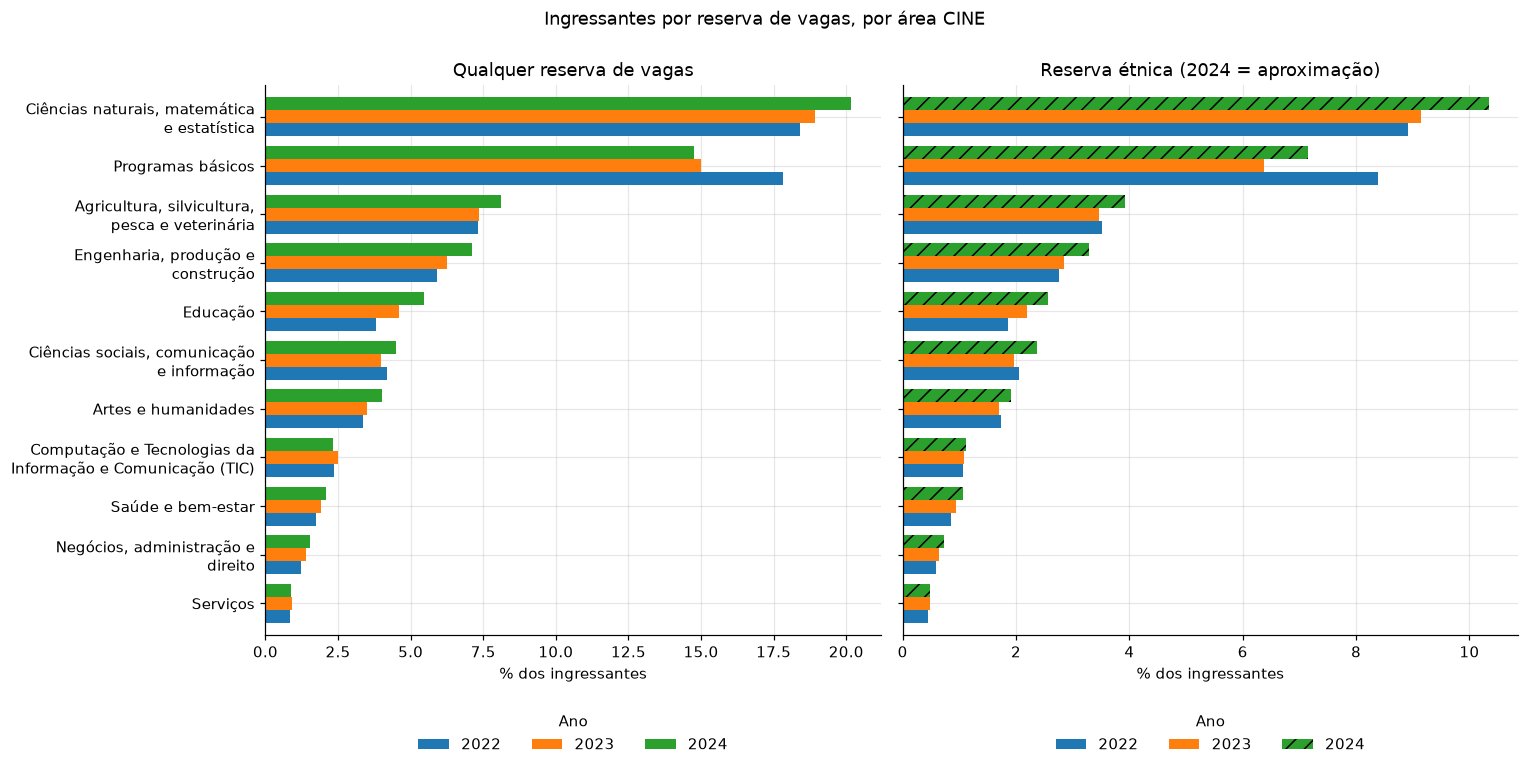

In [10]:
# Figura 3b: reserva de vagas e reserva étnica por área
ordem_areas = a3.pivot(index="area_geral", columns="ano", values="pct_reserva_vaga").sort_values(2024).index

fig, eixos = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
for eixo, coluna, titulo in [
    (eixos[0], "pct_reserva_vaga", "Qualquer reserva de vagas"),
    (eixos[1], "pct_reserva_etnica", "Reserva étnica (2024 = aproximação)"),
]:
    pivo = a3.pivot(index="area_geral", columns="ano", values=coluna).loc[ordem_areas]
    pivo.index = quebrar(pivo.index)
    pivo.plot(kind="barh", ax=eixo, width=0.8)
    eixo.set_title(titulo)
    eixo.set_xlabel("% dos ingressantes")
    eixo.set_ylabel("")
    if coluna == "pct_reserva_etnica":
        for barra in eixo.containers[-1]:  # barras de 2024
            barra.set_hatch("//")
    eixo.legend(title="Ano", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
fig.suptitle("Ingressantes por reserva de vagas, por área CINE", y=1.0)
fig.tight_layout()
fig.savefig(PASTA_FIG / "analise3b_reserva_area.png", dpi=200, bbox_inches="tight")
plt.show()

### Insight da análise 3

- **Resultado principal:** pretos, pardos e indígenas declarados passam de 34,10% para 36,02% dos ingressantes (+1,92 p.p.). A reserva de vagas vai de 2,79% para 3,42%, e a reserva étnica de 1,34% para 1,66%.
- **Tendência por área:** os maiores aumentos de participação foram em Computação (+3,38 p.p.), Educação (+3,15), Artes e humanidades (+3,13) e Serviços (+3,07). Saúde e bem-estar foi a única área com queda (-0,33 p.p.). Excluindo Programas básicos, a distância entre a maior e a menor participação caiu de 9,01 para 8,18 p.p.
- **Exceção ou ponto de atenção:** a reserva de vagas é muito concentrada: 20,18% dos ingressantes em Ciências naturais, contra 1,52% em Negócios e 0,88% em Serviços. Essa ordem não acompanha a participação de pretos, pardos e indígenas, e vale testar a hipótese de ligação com a oferta em instituições públicas, cruzando com a rede da IES. A reserva étnica equivale a cerca de 4% a 5% dos pretos, pardos e indígenas declarados, então os dois indicadores medem coisas diferentes.
- **Mudança de colunas (item 17 dos slides):** a coluna única de reserva étnica deixou de existir em 2024 e foi unificada em `qt_ing_reserva_etnica` (2022 e 2023 = coluna antiga; 2024 = `RVPPI + RVQUILO + RVPOVT`). A série subiu +0,11 p.p. em 2023 e +0,21 p.p. em 2024. A coluna de reserva de vagas, que não foi substituída, também acelerou (+0,29 e +0,34 p.p.), o que sugere, sem provar, que parte do aumento de 2024 é real.
- **Limitações:** o denominador inclui ingressantes sem cor/raça declarada; a reserva étnica de 2024 é aproximação, com risco de dupla contagem entre grupos; a área CINE é a vigente em cada ano (219 cursos mudaram de área geral); Programas básicos tem poucos ingressantes (29 mil a 44 mil) e oscila muito.